**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**08 | Out-of-Fold Confidence and Subject-Disjoint Temperature Calibration**

![HARTH confidence and temperature calibration workflow](../../images/08_consolidated_workflow.svg)

**Objective:** Assess the softmax confidence and errors of weighted temporal CNNs on held-out HARTH Development participants, then separately evaluate scalar temperature scaling fitted using participant-disjoint Calibration data.

**Data and boundaries:** Official NTNU AI Lab HARTH v2.0, eight documented activity classes, six 50 Hz lower-back/thigh accelerometer channels, **29 Development participants**, **14,201 base** and **28,201 expanded** label-pure windows. S023 and S032 are excluded. Both experiments use three participant-disjoint outer folds and 400 optimiser updates per CNN.

**Experiment A — Uncalibrated confidence audit:** On **14,201** out-of-fold windows, the separately fitted confidence-audit CNNs achieve **accuracy 0.9457**, ten-bin **ECE 0.0454**, multiclass **Brier 0.0907**, and **39 incorrect predictions with confidence at least 0.90**. Shuffling recall is only **0.1187** (219 source windows).

**Experiment B — Subject-disjoint temperature scaling:** Three *new* CNNs are fitted with separate model-Train, Calibration and outer Validation participants. The fitted temperatures are **0.6274**, **0.3973** and **0.5050**. On outer Validation participants, the **mean of fold ECE decreases 0.0494 → 0.0286**, Brier decreases **0.1085 → 0.1044**, but NLL increases **0.2494 → 0.2580**. Accuracy remains **0.9275**; Fold 1 worsens on all three probability metrics.

**Evidence scope:** The two experiments use different fitted CNN populations and must not be compared as if their uncalibrated predictions came from the same model. All metrics are Development-only, not externally verified uncertainty or prospective performance.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# -------------------- 3. Machine Learning and Evaluation ---------------------
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.metrics import f1_score

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)

# ---------------------- 5. HARTH and Research Utilities ----------------------
from harth_data import (
    HARTH_SUBJECTS, ACTIVITY_NAMES, SENSOR_COLUMNS,
    prepare_harth_nested_window_cohort,
)
from core.temporal_cnn import (
    train_temporal_cnn_fixed_steps, predict_temporal_cnn_probabilities,
)
from core.prediction_reliability import audit_prediction_confidence
from core.temperature_calibration import (
    fit_temperature, apply_temperature, multiclass_nll,
)
from core.output_download import download_outputs_from_colab

# ------------------------ 6. Device and Output Folder ------------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)


Repository up to date.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Prepare Shared Nested Development Windows**

Reconstruct timestamp-continuous, single-label 100-sample windows (50 Hz, 50-sample stride) from the official HARTH recordings. Preserve original activity labels, participant identities and source rows. Base 500-cap windows are contained in each participant's expanded 1,000-cap cohort.

**Executed cohort:** **29 Development participants**, **14,201 base windows** and **28,201 expanded windows**. Source codes not defined among the eight selected activities are retained for the source audit rather than assigned invented task labels. The reserved S023/S032 participants are not loaded. Both experiments reuse these source rows and outer folds, but train separate CNNs.


In [3]:
# =============== 02. Prepare Shared Nested Development Windows ===============

# --------------------- 1. Define Development Population ----------------------
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))

# ------------------- 2. Construct Strictly Nested Windows --------------------
X, metadata, overview = prepare_harth_nested_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    base_cap=500, expanded_cap=1000,
    window_size=100, step_size=50, sampling_rate=50,
)
base_rows = np.flatnonzero(metadata["in_base_500"].to_numpy(dtype=bool))
y = metadata["label"].to_numpy()
group_ids = metadata["subject_id"].to_numpy()

# ---------------------- 3. Protect Source-Row Alignment ----------------------
if len(X) != len(metadata) or X.shape[1:] != (len(SENSOR_COLUMNS), 100):
    raise ValueError("HARTH source windows and metadata are misaligned.")
if not len(base_rows) or set(group_ids) & RESERVED_TEST:
    raise ValueError("The Development population is empty or includes Test.")
if not np.isin(y, TASK_CLASSES).all():
    raise ValueError("A retained window has an undefined activity label.")

# --------------------- 4. Configure Matching Outer Folds ---------------------
FOLDS, STEPS = 3, 400
outer_folds = list(GroupKFold(n_splits=FOLDS).split(
    np.zeros(len(base_rows)), y[base_rows], groups=group_ids[base_rows],
))
print("Development people:", len(set(group_ids)))
print("Base and expanded source windows:", len(base_rows), len(X))
display(overview.head())


Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Downloaded 50,898,931 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 sa

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Reje

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Development people: 29
Base and expanded source windows: 14201 28201


,subject_id,eligible_windows,base_windows,expanded_windows,new_training_windows
0,S006,6708,500,1000,500
1,S008,7392,500,1000,500
2,S009,201,201,201,0
3,S010,6077,500,1000,500
4,S012,7309,500,1000,500


**03. Generate Uncalibrated Out-of-Fold CNN Probabilities**

For each of the three participant-disjoint outer folds, fit one inverse-square-root-weighted temporal CNN on expanded windows from its Training participants and predict the held-out base-cap windows. All models use **400 optimiser updates**, batch size **128**, learning rate **0.001** and seed **42**. Scaling and class weighting use each fold's Training data only.

**Executed held-out folds:** **5,000**, **4,701** and **4,500** windows from **10**, **10** and **nine** Validation participants, respectively. Fold Macro F1 values are **0.7591**, **0.7974** and **0.8196**. The resulting uncalibrated softmax vectors are saved with source-row identifiers and a fixed eight-class probability-column order.


In [4]:
# ========== 03. Generate Uncalibrated Out-of-Fold CNN Probabilities ==========

# ------------------------- 1. Fit Three Outer Models -------------------------
confidence_records = []
confidence_fold_metrics = []

for fold, (train, valid) in enumerate(outer_folds, start=1):
    base_train = base_rows[train]
    validation = base_rows[valid]
    train_subjects = set(group_ids[base_train])
    validation_subjects = set(group_ids[validation])
    if train_subjects & validation_subjects:
        raise ValueError("Training and held-out participants overlap.")
    train_rows = np.flatnonzero(np.isin(group_ids, list(train_subjects)))

    model, history, predicted, train_stats = train_temporal_cnn_fixed_steps(
        X_train=X[train_rows], y_train=y[train_rows],
        X_validation=X[validation], y_validation=y[validation],
        classes=TASK_CLASSES, max_steps=STEPS, eval_every=100,
        batch_size=128, learning_rate=1e-3, seed=42,
        device=DEVICE, class_weighting="inverse_sqrt",
    )
    probabilities = predict_temporal_cnn_probabilities(
        model, X[validation], train_stats, TASK_CLASSES,
        batch_size=256, device=DEVICE,
    )
    if not np.array_equal(
        np.asarray(TASK_CLASSES)[probabilities.argmax(axis=1)], predicted
    ):
        raise ValueError("Softmax and final-step predictions disagree.")
    confidence_records.append(pd.DataFrame({
        "fold": fold, "source_row": validation,
        "subject_id": group_ids[validation],
        "true_label": y[validation],
        **{f"prob_{code}": probabilities[:, j]
           for j, code in enumerate(TASK_CLASSES)},
    }))
    confidence_fold_metrics.append({
        "fold": fold,
        "validation_subjects": len(validation_subjects),
        "validation_windows": len(validation),
        "macro_f1": f1_score(
            y[validation], predicted, labels=TASK_CLASSES,
            average="macro", zero_division=0,
        ),
    })
    print("Completed uncalibrated confidence fold:", fold)

# ---------------------- 2. Combine Held-Out Source Rows ----------------------
confidence_oof = pd.concat(
    confidence_records, ignore_index=True
).sort_values("source_row").reset_index(drop=True)
display(pd.DataFrame(confidence_fold_metrics).round(4))


Step 100/400 | loss=0.8877 | Validation Macro F1=0.5862
Step 200/400 | loss=0.4701 | Validation Macro F1=0.7494
Step 300/400 | loss=0.3450 | Validation Macro F1=0.7403
Step 400/400 | loss=0.2571 | Validation Macro F1=0.7591
Completed uncalibrated confidence fold: 1
Step 100/400 | loss=0.8686 | Validation Macro F1=0.5879
Step 200/400 | loss=0.4489 | Validation Macro F1=0.6823
Step 300/400 | loss=0.3275 | Validation Macro F1=0.7782
Step 400/400 | loss=0.2570 | Validation Macro F1=0.7974
Completed uncalibrated confidence fold: 2
Step 100/400 | loss=0.8687 | Validation Macro F1=0.5765
Step 200/400 | loss=0.4949 | Validation Macro F1=0.6084
Step 300/400 | loss=0.3644 | Validation Macro F1=0.7372
Step 400/400 | loss=0.3287 | Validation Macro F1=0.8196
Completed uncalibrated confidence fold: 3


,fold,validation_subjects,validation_windows,macro_f1
0,1,10,5000,0.7591
1,2,10,4701,0.7974
2,3,9,4500,0.8196


**04. Verify Source Alignment and Audit Softmax Reliability**

Check one-to-one source-row coverage, original label agreement and distinct held-out participant identities before interpreting probabilities. Ten-bin expected calibration error (ECE) and multiclass Brier are window-pooled descriptive measures, sensitive to support and bin definitions.

**Observed overall confidence-audit metrics (14,201 windows):** Accuracy **0.9457**, mean maximum softmax probability **0.9003**, ten-bin ECE **0.0454** and multiclass Brier **0.0907**. There are **39 wrong predictions with confidence at least 0.90**. Accuracy being greater than mean confidence indicates overall lower reported confidence than observed accuracy for this sample; it does not imply the model is calibrated for every person or activity.


In [5]:
# ========= 04. Verify Source Alignment and Audit Softmax Reliability =========

# ----------------------- 1. Check Held-Out Provenance ------------------------
if len(confidence_oof) != len(base_rows):
    raise ValueError("Uncalibrated out-of-fold row count is incomplete.")
if not confidence_oof["source_row"].is_unique:
    raise ValueError("Duplicate source rows in confidence evidence.")
np.testing.assert_array_equal(
    confidence_oof["source_row"].to_numpy(), np.sort(base_rows),
)
np.testing.assert_array_equal(
    confidence_oof["true_label"].to_numpy(), y[np.sort(base_rows)],
)

# --------------------- 2. Compute Confidence Diagnostics ---------------------
confidence_prob_columns = [f"prob_{code}" for code in TASK_CLASSES]
(
    confidence_details, confidence_reliability,
    confidence_by_subject, confidence_summary,
) = audit_prediction_confidence(
    y_true=confidence_oof["true_label"].to_numpy(),
    probabilities=confidence_oof[confidence_prob_columns].to_numpy(),
    subjects=confidence_oof["subject_id"].to_numpy(),
    classes=TASK_CLASSES, n_bins=10,
)
confidence_details["fold"] = confidence_oof["fold"].to_numpy()
confidence_details["source_row"] = confidence_oof["source_row"].to_numpy()

# ------------------------ 3. Inspect Recorded Metrics ------------------------
display(pd.DataFrame([confidence_summary]).round(4))
display(confidence_reliability.round(4))


,windows,accuracy,mean_confidence,ece_10_bins,multiclass_brier,high_confidence_errors_0_90
0,14201,0.9457,0.9003,0.0454,0.0907,39


,bin,lower,upper,windows,mean_confidence,observed_accuracy
0,0,0.0,0.1,0,NaN,NaN
1,1,0.1,0.2,0,NaN,NaN
2,2,0.2,0.3,52,0.2754,0.4038
3,3,0.3,0.4,285,0.3581,0.4561
4,4,0.4,0.5,355,0.4528,0.5634
5,5,0.5,0.6,399,0.5506,0.7043
6,6,0.6,0.7,455,0.6510,0.7780
7,7,0.7,0.8,777,0.7572,0.8674
8,8,0.8,0.9,1580,0.8568,0.9563
9,9,0.9,1.0,10298,0.9759,0.9962


**05. Visualise Uncalibrated Reliability and Confidence**

The ten-bin reliability diagram compares mean predicted confidence with the observed proportion correct. Correct and incorrect windows are also displayed by maximum softmax probability.

**Observed distribution:** **10,298 of 14,201** windows fall in the **0.90–1.00** confidence bin, which has mean confidence **0.9759** and observed accuracy **0.9962**. These pooled averages can hide participant- or class-specific miscalibration. Zero-count bins are not evidence of calibrated predictions, and overlapping windows are not independent observations.


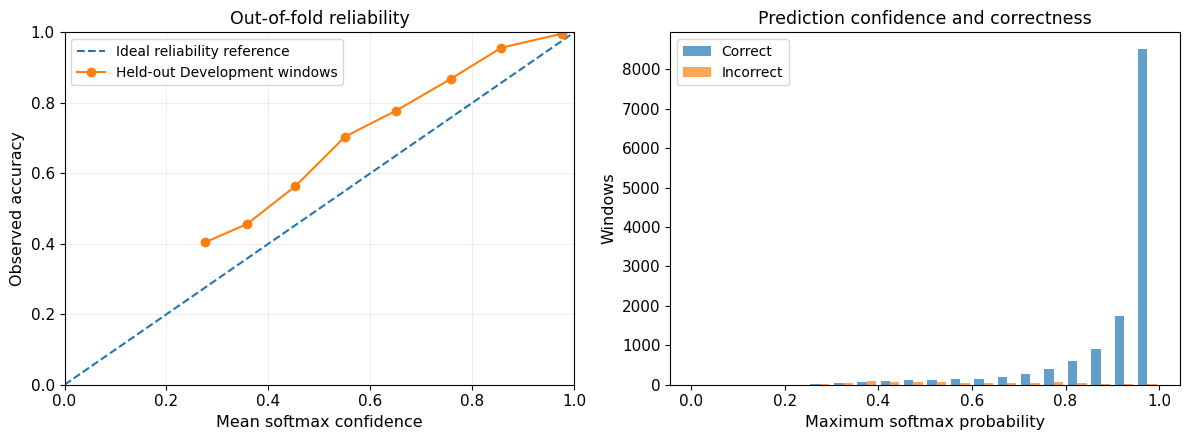

In [6]:
# =========== 05. Visualise Uncalibrated Reliability and Confidence ===========

# -------------------------- 1. Reliability Diagram ---------------------------
used_bins = confidence_reliability.loc[
    confidence_reliability["windows"] > 0
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot([0, 1], [0, 1], linestyle="--",
             label="Ideal reliability reference")
axes[0].plot(
    used_bins["mean_confidence"], used_bins["observed_accuracy"],
    marker="o", label="Held-out Development windows",
)
axes[0].set(xlim=(0, 1), ylim=(0, 1),
            xlabel="Mean softmax confidence", ylabel="Observed accuracy",
            title="Out-of-fold reliability")
axes[0].legend()
axes[0].grid(alpha=0.2)

# ------------------ 2. Correct Versus Incorrect Confidence -------------------
correct = confidence_details.loc[
    confidence_details["correct"], "confidence"
]
wrong = confidence_details.loc[
    ~confidence_details["correct"], "confidence"
]
axes[1].hist([correct, wrong], bins=np.linspace(0, 1, 21),
             label=["Correct", "Incorrect"], alpha=0.7)
axes[1].set(xlabel="Maximum softmax probability", ylabel="Windows",
            title="Prediction confidence and correctness")
axes[1].legend()
fig.tight_layout()
save_figure(fig, output_dir / "08_confidence_reliability.png")
plt.show()


**06. Inspect Minority-Class Errors and Confident Mistakes**

Inspect support, recall and high-confidence incorrect decisions by activity and participant. The threshold **0.90** is a descriptive auditing threshold, not a deployed rejection or decision policy.

**Minority classes:** Shuffling recall **0.1187** on **219** windows (**193** errors, **eight** high-confidence errors). Stairs ascending recall **0.7344** on **192** windows; Stairs descending recall **0.6538** on **182** windows, with **eight** high-confidence errors. For comparison, Running recall is **0.9951** on **1,028** windows.

**Error concentration:** **20 of the 39** high-confidence mistakes are **Standing predicted as Sitting**; another **eight** are Stairs descending predicted as Walking. Results vary by participant; high pooled accuracy does not establish satisfactory rare-class or individual-level reliability.


In [7]:
# ========= 06. Inspect Minority-Class Errors and Confident Mistakes ==========

# ----------------------- 1. Class-Level Error Summary ------------------------
class_rows = []
for code in TASK_CLASSES:
    part = confidence_details.loc[
        confidence_details["true_label"] == code
    ]
    mistakes = part.loc[~part["correct"]]
    class_rows.append({
        "class": ACTIVITY_NAMES[code],
        "support": len(part),
        "recall": float(part["correct"].mean()) if len(part) else np.nan,
        "errors": len(mistakes),
        "high_confidence_errors_0_90": int(
            (mistakes["confidence"] >= 0.90).sum()
        ),
        "mean_error_confidence": (
            float(mistakes["confidence"].mean()) if len(mistakes) else np.nan
        ),
    })
confidence_class_report = pd.DataFrame(class_rows)
display(confidence_class_report.round(4))

# ------------------------ 2. Participant-Level Errors ------------------------
display(
    confidence_by_subject.sort_values(
        "high_confidence_errors", ascending=False
    ).round(4)
)

# ----------------------- 3. Confident Confusion Pairs ------------------------
confident_errors = confidence_details.loc[
    (~confidence_details["correct"]) &
    (confidence_details["confidence"] >= 0.90)
]
confidence_confusion_pairs = (
    confident_errors.groupby(["true_label", "predicted_label"])
    .size().rename("windows").reset_index()
    .sort_values("windows", ascending=False)
)
display(confidence_confusion_pairs.head(15))


,class,support,recall,errors,high_confidence_errors_0_90,mean_error_confidence
0,Walking,3591,0.9287,256,3,0.4852
1,Running,1028,0.9951,5,0,0.5505
2,Shuffling,219,0.1187,193,8,0.5634
3,Stairs ascending,192,0.7344,51,0,0.5140
4,Stairs descending,182,0.6538,63,8,0.6734
5,Standing,2227,0.9555,99,20,0.5756
6,Sitting,5599,0.9816,103,0,0.7292
7,Lying,1163,0.9991,1,0,0.5305


,subject_id,windows,accuracy,errors,mean_error_confidence,high_confidence_errors
26,S036,500,0.9340,33,0.5813,9
9,S017,500,0.9320,34,0.6799,7
5,S013,500,0.9120,44,0.5535,5
10,S018,500,0.9360,32,0.6907,5
0,S006,500,0.9740,13,0.5139,3
6,S014,500,0.9380,31,0.5099,2
2,S009,201,0.8955,21,0.6008,2
16,S025,500,0.9640,18,0.6455,2
7,S015,500,0.9720,14,0.6641,1
13,S021,500,0.9220,39,0.5724,1


,true_label,predicted_label,windows
5,6,7,20
4,5,1,8
2,3,6,4
0,1,6,3
1,3,1,2
3,3,7,2


**07. Export Uncalibrated Confidence Evidence**

Save current fold metrics, class-aligned uncalibrated out-of-fold probabilities, window-level error details, reliability bins, participant metrics, the eight-class error summary and high-confidence confusion pairs under the `08_confidence_` output family.

The files record **14,201 held-out base windows** and **39 high-confidence mistakes**. They are outputs of Experiment A only; no temperature is fitted using these out-of-fold predictions, and they must not be described as the raw arm of Experiment B.


In [8]:
# ================ 07. Export Uncalibrated Confidence Evidence ================

# ----------------------- 1. Summarise Confidence Audit -----------------------
print("Out-of-fold confidence windows:", len(confidence_oof))
print("Contributing Development participants:",
      confidence_details["subject_id"].nunique())
print("High-confidence mistakes:",
      confidence_summary["high_confidence_errors_0_90"])

# ------------------------- 2. Save Confidence Tables -------------------------
overview.to_csv(
    output_dir / "08_development_cohort_summary.csv", index=False
)
pd.DataFrame(confidence_fold_metrics).to_csv(
    output_dir / "08_confidence_fold_metrics.csv", index=False
)
confidence_oof.to_csv(
    output_dir / "08_confidence_oof_class_probabilities.csv", index=False
)
confidence_details.to_csv(
    output_dir / "08_confidence_prediction_details.csv", index=False
)
confidence_reliability.to_csv(
    output_dir / "08_confidence_reliability_bins.csv", index=False
)
confidence_by_subject.to_csv(
    output_dir / "08_confidence_subject_metrics.csv", index=False
)
pd.DataFrame([confidence_summary]).to_csv(
    output_dir / "08_confidence_summary.csv", index=False
)
confidence_class_report.to_csv(
    output_dir / "08_confidence_class_error_summary.csv", index=False
)
confidence_confusion_pairs.to_csv(
    output_dir / "08_confidence_high_confidence_error_pairs.csv", index=False
)


Out-of-fold confidence windows: 14201
Contributing Development participants: 29
High-confidence mistakes: 39


**08. Fit Subject-Disjoint Temperature Scaling**

Within each of the three outer GroupKFold partitions, reserve approximately 20% of the remaining participants for Calibration using a participant-grouped inner split. Fit a **new** weighted CNN on the expanded windows of the remaining model-Train participants, then optimise a positive scalar temperature using *base-cap Calibration labels only*. Evaluate both probability conditions on untouched outer Validation participants.

**Executed participant allocation:** Fold 1 has **15 Train / four Calibration / 10 outer Validation** people; Fold 2 also **15 / four / 10**; Fold 3 **16 / four / nine**. Each Calibration group has **2,000 windows**. The fitted temperatures are **0.6274**, **0.3973** and **0.5050**, respectively. Every temperature is below one, which sharpens the recorded probability distribution without changing the top-1 class.

The Calibration partition is used for fitting and is not the outer held-out evidence.


In [9]:
# =============== 08. Fit Subject-Disjoint Temperature Scaling ================

# ---------------- 1. Prepare Separate Calibration Experiment -----------------
calibration_records = []
calibration_fold_records = []
calibration_subject_assignments = []

# ------------------- 2. Fit Models and Temperature Scalars -------------------
for fold, (outer_train, outer_valid) in enumerate(outer_folds, start=1):
    outer_train_rows = base_rows[outer_train]
    validation_rows = base_rows[outer_valid]
    inner = GroupShuffleSplit(
        n_splits=1, test_size=0.2, random_state=42 + fold,
    )
    inner_train, inner_cal = next(inner.split(
        np.zeros(len(outer_train_rows)),
        y[outer_train_rows], groups=group_ids[outer_train_rows],
    ))
    train_people = set(group_ids[outer_train_rows[inner_train]])
    cal_people = set(group_ids[outer_train_rows[inner_cal]])
    valid_people = set(group_ids[validation_rows])
    if train_people & cal_people or train_people & valid_people:
        raise ValueError("Calibration Train participants are not disjoint.")
    if cal_people & valid_people:
        raise ValueError("Calibration participants overlap outer Validation.")

    for role, people in (
        ("train", train_people),
        ("calibration", cal_people),
        ("outer_validation", valid_people),
    ):
        calibration_subject_assignments.extend(
            {"fold": fold, "role": role, "subject_id": person}
            for person in sorted(people)
        )

    train_rows = np.flatnonzero(
        np.isin(group_ids, list(train_people))
    )
    cal_rows = outer_train_rows[inner_cal]
    if not set(TASK_CLASSES).issubset(set(y[train_rows])):
        raise ValueError("The CNN Train partition lacks a target activity.")

    print(
        f"Fold {fold}: Train {len(train_people)}, "
        f"Calibration {len(cal_people)}, "
        f"outer Validation {len(valid_people)} participants"
    )
    model, history, _, stats = train_temporal_cnn_fixed_steps(
        X[train_rows], y[train_rows], X[cal_rows], y[cal_rows],
        classes=TASK_CLASSES, max_steps=STEPS, eval_every=STEPS,
        batch_size=128, learning_rate=1e-3, seed=42,
        device=DEVICE, class_weighting="inverse_sqrt",
    )
    cal_prob = predict_temporal_cnn_probabilities(
        model, X[cal_rows], stats, TASK_CLASSES, device=DEVICE,
    )
    fitted = fit_temperature(cal_prob, y[cal_rows], TASK_CLASSES)
    raw = predict_temporal_cnn_probabilities(
        model, X[validation_rows], stats, TASK_CLASSES, device=DEVICE,
    )
    scaled = apply_temperature(raw, fitted["temperature"])

    for method, probabilities in (
        ("Uncalibrated", raw),
        ("Temperature scaled", scaled),
    ):
        _, _, _, metrics = audit_prediction_confidence(
            y[validation_rows], probabilities,
            group_ids[validation_rows], TASK_CLASSES,
        )
        calibration_fold_records.append({
            "fold": fold, "method": method,
            "temperature": fitted["temperature"],
            "calibration_windows": fitted["calibration_windows"],
            "calibration_nll_before": fitted["calibration_nll_before"],
            "calibration_nll_after": fitted["calibration_nll_after"],
            "train_subjects": len(train_people),
            "calibration_subjects": len(cal_people),
            "validation_subjects": len(valid_people),
            "validation_windows": len(validation_rows),
            "nll": multiclass_nll(
                y[validation_rows], probabilities, TASK_CLASSES
            ),
            "ece": metrics["ece_10_bins"],
            "brier": metrics["multiclass_brier"],
            "accuracy": metrics["accuracy"],
        })
        calibration_records.append(pd.DataFrame({
            "fold": fold, "method": method,
            "source_row": validation_rows,
            "subject_id": group_ids[validation_rows],
            "true_label": y[validation_rows],
            **{f"prob_{code}": probabilities[:, j]
               for j, code in enumerate(TASK_CLASSES)},
        }))

# -------------------- 3. Combine Outer Held-Out Evidence ---------------------
calibration_fold_results = pd.DataFrame(calibration_fold_records)
calibration_oof = pd.concat(calibration_records, ignore_index=True)
display(calibration_fold_results.round(4))


Fold 1: Train 15, Calibration 4, outer Validation 10 participants
Step 400/400 | loss=0.4655 | Validation Macro F1=0.7456
Fold 2: Train 15, Calibration 4, outer Validation 10 participants
Step 400/400 | loss=0.4938 | Validation Macro F1=0.8272
Fold 3: Train 16, Calibration 4, outer Validation 9 participants
Step 400/400 | loss=0.4890 | Validation Macro F1=0.7707


,fold,method,temperature,calibration_windows,calibration_nll_before,calibration_nll_after,train_subjects,calibration_subjects,validation_subjects,validation_windows,nll,ece,brier,accuracy
0,1,Uncalibrated,0.6274,2000,0.3801,0.3430,15,4,10,5000,0.3301,0.0341,0.1467,0.8904
1,1,Temperature scaled,0.6274,2000,0.3801,0.3430,15,4,10,5000,0.3835,0.0470,0.1516,0.8904
2,2,Uncalibrated,0.3973,2000,0.0976,0.0452,15,4,10,4701,0.2195,0.0723,0.0938,0.9477
3,2,Temperature scaled,0.3973,2000,0.0976,0.0452,15,4,10,4701,0.1997,0.0164,0.0792,0.9477
4,3,Uncalibrated,0.5050,2000,0.2727,0.1933,16,4,9,4500,0.1988,0.0419,0.0849,0.9444
5,3,Temperature scaled,0.5050,2000,0.2727,0.1933,16,4,9,4500,0.1909,0.0225,0.0825,0.9444


**09. Compare Held-Out Calibration Metrics by Fold**

Compare outer-held-out negative log-likelihood (NLL), ten-bin ECE, multiclass Brier and top-1 accuracy for the *same* source windows under uncalibrated and temperature-scaled probabilities from Experiment B. Report means over three folds separately from pooled reliability.

| Metric, three-fold mean | Uncalibrated | Temperature scaled |
| --- | ---: | ---: |
| NLL ↓ | **0.2494** | 0.2580 |
| ECE ↓ | 0.0494 | **0.0286** |
| Multiclass Brier ↓ | 0.1085 | **0.1044** |
| Accuracy ↑ | 0.9275 | 0.9275 |

**Not uniform improvement:** Fold 1 has worse held-out NLL (**0.3301 → 0.3835**), ECE (**0.0341 → 0.0470**) and Brier (**0.1467 → 0.1516**) after scaling, whereas Folds 2 and 3 improve on all three. Improvements in fitting-partition NLL do not guarantee held-out NLL improvements.


nll                             ece               \
method Temperature scaled Uncalibrated Temperature scaled Uncalibrated   
fold                                                                     
1                  0.3835       0.3301             0.0470       0.0341   
2                  0.1997       0.2195             0.0164       0.0723   
3                  0.1909       0.1988             0.0225       0.0419   

                    brier                        accuracy               
method Temperature scaled Uncalibrated Temperature scaled Uncalibrated  
fold                                                                    
1                  0.1516       0.1467             0.8904       0.8904  
2                  0.0792       0.0938             0.9477       0.9477  
3                  0.0825       0.0849             0.9444       0.9444

,nll,ece,brier,accuracy
method,,,,
Temperature scaled,0.2580,0.0286,0.1044,0.9275
Uncalibrated,0.2494,0.0494,0.1085,0.9275


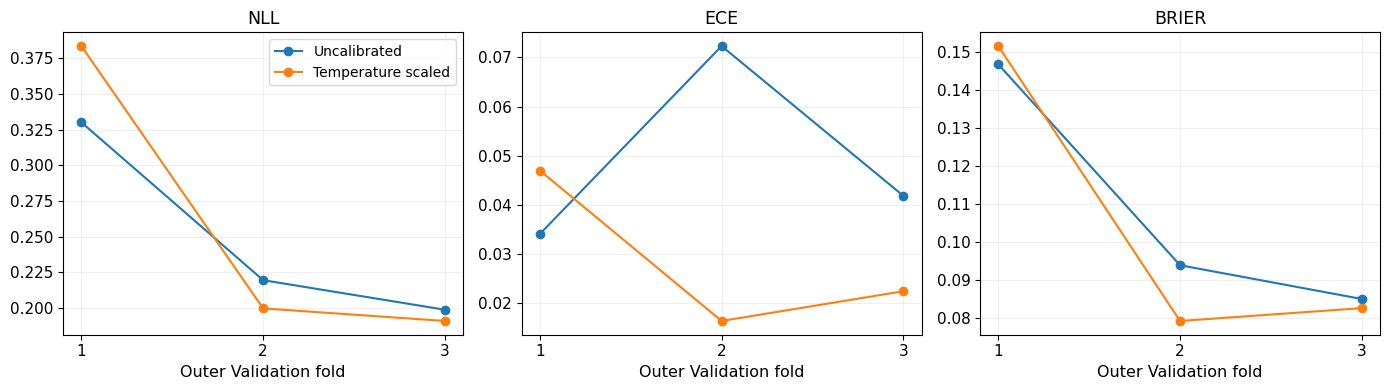

In [10]:
# ============= 09. Compare Held-Out Calibration Metrics by Fold ==============

# ---------------------- 1. Review Matched Fold Outcomes ----------------------
calibration_comparison = calibration_fold_results.pivot(
    index="fold", columns="method",
    values=["nll", "ece", "brier", "accuracy"],
)
display(calibration_comparison.round(4))
calibration_means = calibration_fold_results.groupby("method")[
    ["nll", "ece", "brier", "accuracy"]
].mean()
display(calibration_means.round(4))

# ------------------ 2. Plot Fold-Level Probability Metrics -------------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["nll", "ece", "brier"]):
    for method, frame in calibration_fold_results.groupby(
        "method", sort=False
    ):
        ax.plot(frame["fold"], frame[metric], marker="o", label=method)
    ax.set(title=metric.upper(), xlabel="Outer Validation fold",
           xticks=list(range(1, FOLDS + 1)))
    ax.grid(alpha=0.2)
axes[0].legend()
fig.tight_layout()
save_figure(fig, output_dir / "08_calibration_fold_metrics.png")
plt.show()


**10. Inspect Out-of-Fold Reliability Before and After Scaling**

Construct reliability curves for both conditions using the **14,201 common outer-held-out base windows** of Experiment B, keeping prediction labels, participant identifiers and class columns aligned.

**Interpretation:** The mean of three held-out fold ECE values improves (**0.0494 → 0.0286**), but ECE computed from all pooled out-of-fold windows is a different aggregate and may not equal that fold mean. Scaling concentrates many predictions in the highest-confidence bin. A positive scalar temperature preserves the top-1 class; it does not ensure that predicted probabilities better reflect every activity or participant.


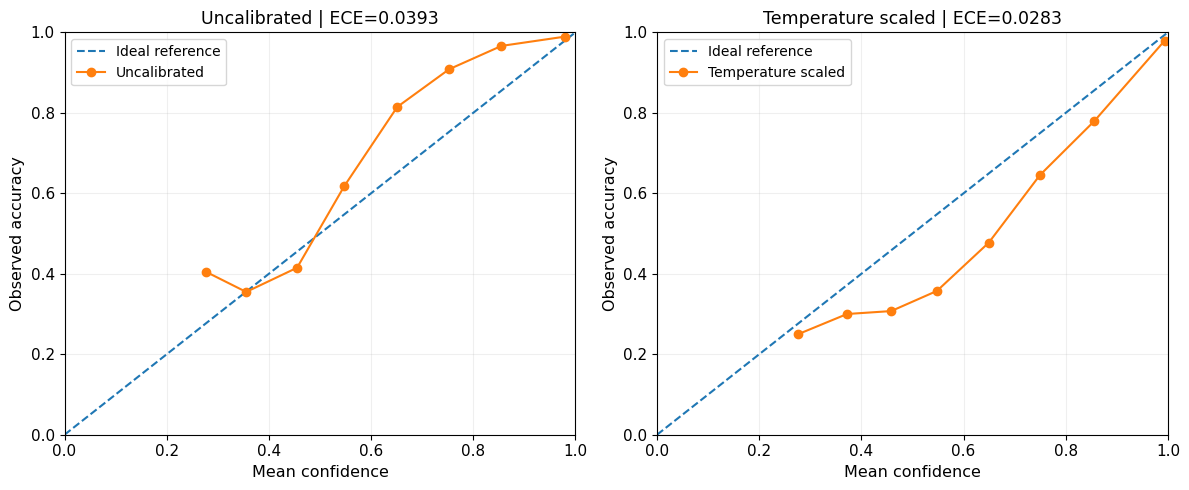

In [11]:
# ======= 10. Inspect Out-of-Fold Reliability Before and After Scaling ========

# ------------------------ 1. Audit Paired Reliability ------------------------
calibration_reliability_tables = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cal_prob_columns = [f"prob_{code}" for code in TASK_CLASSES]
for ax, (method, subset) in zip(
    axes, calibration_oof.groupby("method", sort=False)
):
    subset = subset.sort_values("source_row")
    probabilities = subset[cal_prob_columns].to_numpy()
    _, bins, _, metrics = audit_prediction_confidence(
        subset["true_label"].to_numpy(), probabilities,
        subset["subject_id"].to_numpy(), TASK_CLASSES,
    )
    filled = bins.loc[bins["windows"] > 0]
    calibration_reliability_tables.append(bins.assign(method=method))
    ax.plot([0, 1], [0, 1], "--", label="Ideal reference")
    ax.plot(
        filled["mean_confidence"], filled["observed_accuracy"],
        marker="o", label=method,
    )
    ax.set(
        xlim=(0, 1), ylim=(0, 1),
        title=f"{method} | ECE={metrics['ece_10_bins']:.4f}",
        xlabel="Mean confidence", ylabel="Observed accuracy",
    )
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "08_calibration_reliability.png")
plt.show()


**11. Verify and Export Disjoint-Subject Calibration Evidence**

Verify that each of the two probability conditions covers every original base source row once, has the same true labels and preserves predicted class. Ensure the fitted scalar temperatures are positive and that model-Train, Calibration and outer Validation participant sets do not overlap within a fold.

The recorded `08_calibration_` tables contain six fold/method metric records, the **87 participant-role assignments across three outer folds**, **28,402 probability rows (14,201 per condition)**, three-fold mean metrics and paired reliability-bin summaries. These outputs describe Experiment B, with different CNN training membership from the uncalibrated confidence audit.


In [12]:
# ======== 11. Verify and Export Disjoint-Subject Calibration Evidence ========

# ----------------- 1. Check Alignment and Top-1 Preservation -----------------
expected_rows = set(base_rows.tolist())
for method, table in calibration_oof.groupby("method"):
    if not table["source_row"].is_unique:
        raise ValueError(f"Duplicated held-out source rows for {method}.")
    if set(table["source_row"]) != expected_rows:
        raise ValueError(f"Unmatched outer-held-out rows for {method}.")
    if set(table["subject_id"]) & RESERVED_TEST:
        raise ValueError("Reserved Test participants entered calibration.")

uncalibrated = calibration_oof.loc[
    calibration_oof["method"] == "Uncalibrated"
].sort_values("source_row")
temperature_scaled = calibration_oof.loc[
    calibration_oof["method"] == "Temperature scaled"
].sort_values("source_row")
raw_scores = uncalibrated[cal_prob_columns].to_numpy()
scaled_scores = temperature_scaled[cal_prob_columns].to_numpy()
np.testing.assert_array_equal(
    uncalibrated["true_label"].to_numpy(),
    temperature_scaled["true_label"].to_numpy(),
)
np.testing.assert_array_equal(
    raw_scores.argmax(axis=1), scaled_scores.argmax(axis=1),
)
if not calibration_fold_results["temperature"].gt(0).all():
    raise ValueError("All fitted temperatures must be positive.")
if len(calibration_fold_results) != FOLDS * 2:
    raise ValueError("Calibration fold results are incomplete.")

# -------------------- 2. Save Calibration Research Tables --------------------
pd.DataFrame(calibration_subject_assignments).to_csv(
    output_dir / "08_calibration_fold_subject_assignments.csv",
    index=False,
)
calibration_fold_results.to_csv(
    output_dir / "08_calibration_fold_metrics.csv", index=False
)
calibration_means.rename_axis("method").reset_index().to_csv(
    output_dir / "08_calibration_mean_metrics.csv", index=False
)
calibration_oof.to_csv(
    output_dir / "08_calibration_oof_probabilities.csv", index=False
)
pd.concat(calibration_reliability_tables, ignore_index=True).to_csv(
    output_dir / "08_calibration_reliability_bins.csv", index=False
)
print("Saved separate subject-disjoint calibration evidence.")


Saved separate subject-disjoint calibration evidence.


**12. Package Stage 08 Research Outputs**

The executed notebook saves and packages **17 stage-08 CSV/PNG files**: the source-cohort summary, the uncalibrated `08_confidence_` evidence and the separately fitted `08_calibration_` evidence.

The files preserve model-family and evaluation distinctions; a successful package download is not a substitute for independent scientific verification. The CSVs contain the full-precision figures used for the descriptive summaries; no external Test observations or prospectively measured confidence thresholds are introduced.


In [13]:
# =================== 12. Package Stage 08 Research Outputs ===================

# ------------------------ 1. Summarise Model Evidence ------------------------
print("Development participants:", len(DEVELOPMENT_SUBJECTS))
print("Base and expanded windows:", len(base_rows), len(X))
print("Confidence-audit folds:", len(confidence_fold_metrics))
print("Calibration fold/method records:", len(calibration_fold_results))
print("Separate 400-update CNN fits:", FOLDS * 2)

# ------------------------ 2. Package Current Outputs -------------------------
download_outputs_from_colab(
    folder="wearable_activity_recognition/output", stage="08"
)


Development participants: 29
Base and expanded windows: 14201 28201
Confidence-audit folds: 3
Calibration fold/method records: 6
Separate 400-update CNN fits: 6
------------------------------------------------------------------------
Notebook stage: 08
Files packaged: 17
  + 08_calibration_fold_metrics.csv
  + 08_calibration_fold_metrics.png
  + 08_calibration_fold_subject_assignments.csv
  + 08_calibration_mean_metrics.csv
  + 08_calibration_oof_probabilities.csv
  + 08_calibration_reliability.png
  + 08_calibration_reliability_bins.csv
  + 08_confidence_class_error_summary.csv
  + 08_confidence_fold_metrics.csv
  + 08_confidence_high_confidence_error_pairs.csv
  + 08_confidence_oof_class_probabilities.csv
  + 08_confidence_prediction_details.csv
  + 08_confidence_reliability.png
  + 08_confidence_reliability_bins.csv
  + 08_confidence_subject_metrics.csv
  + 08_confidence_summary.csv
  + 08_development_cohort_summary.csv
Download ZIP from Colab Contents: /content/wearable_activity_re

**13. Scientific Interpretation and Research Boundaries**

**Study design:** The official HARTH v2.0 Development cohort includes **29 participants**, **14,201 base** and **28,201 expanded** label-pure windows. Two *separately trained* sets of three weighted temporal CNNs each are used: (A) a full outer-Training-participant uncalibrated confidence audit and (B) a participant-disjoint model-Train/Calibration/outer-Validation temperature-scaling study. Results of the two uncalibrated model populations must not be treated as paired.

**Experiment A: uncalibrated confidence.** Window-level Accuracy is **0.9457**, mean maximum softmax confidence **0.9003**, ten-bin ECE **0.0454** and multiclass Brier **0.0907** on **14,201** held-out Development windows. There are **39** erroneous predictions with confidence at least 0.90. Shuffling recall is only **0.1187** on 219 windows, with 193 mistakes. **20 of the 39** high-confidence mistakes are Standing misclassified as Sitting. High aggregate accuracy does not establish reliable behaviour for rare classes or individual participants.

**Experiment B: subject-disjoint temperature scaling.** Each outer fold withholds four Calibration participants from model Training and fits a positive temperature using their labels only. The fitted values are **0.6274**, **0.3973** and **0.5050**. On the outer Validation folds, mean ECE improves **0.0494 → 0.0286** and mean Brier improves **0.1085 → 0.1044**, but mean NLL worsens **0.2494 → 0.2580**. Fold 1 worsens on all three probability metrics; Folds 2 and 3 improve. Accuracy remains **0.9275** in both conditions, consistent with invariant top-1 labels.

**Interpretation and limits:** These findings are descriptive, single-seed, three-fold Development evidence on correlated overlapping windows with uneven activity support. Ten-bin ECE and the mean of fold metrics depend on the aggregation scheme; Brier and NLL assess different probability properties. Neither experiment establishes calibrated clinical thresholds, uniformly improved individual/class uncertainty, independent external generalisation or real-time reliability. S023 and S032 remain excluded. The saved execution and 17 current output files support these reported results; the original-data experiments were not independently rerun during this documentation revision.
